# E240 — Replicate last-block DINO and test adaptation depth

**complete** · Stage A finished · replication gate missed

2026-11-23T17:59:05+01:00 Stockholm time · Current stage ETA **—**

48/48 trainable trajectories in the current stage · 72 cached raw clips

Twelve new capture-disjoint 768-frame A streams, two independent paired crop draws per walk, and readouts at 48, 96, 192 and 384 optimizer updates. Every policy starts from the same archived pretrained DINO state. Teacher and student each use their own frozen checkpoint readout as the floor. Batch size is two, with two global and four local crops. The EMA cosine horizon is 384 updates in every trained arm.

Separate A, B, C and D holdout panels use native-resolution annotated captures. Each held-out capture belongs to a single regime per walk. The minimum is 30 examples per task class per panel. The fit corpus stays fixed and disjoint. Walk intervals keep the paired crop draws within each walk. Stage A also reports a sensitivity interval that resamples held-out query captures alongside walks, conditional on the fit corpus and panel assignments.

The primary replication readout is the 192-update teacher endpoint, matching E239's horizon. Stage B opens if last-block adaptation improves A by at least +0.20 pp with a positive interval, holds the broad B/C/D mean at or above frozen DINO with a lower bound above −0.20 pp, and beats full adaptation by at least +0.25 pp on B/C/D with a positive interval. A clear deterioration of at least 0.25 pp in any individual held-out regime also closes the gate.

Stage B reuses the exact Stage A full and last-block runs. It adds SSL-head-only, final two blocks, final four blocks and a final-block-only consistency check. Frozen encoder components stay fixed in student and teacher. Stage C opens if two encoder depths on the frontier have reciprocal gains of at least +0.25 pp and positive paired intervals at 192 or 384 updates.

Stage C branches from common last-block checkpoints after 96 and 192 updates. Each branch adapts for 192 further opportunities. The retrospective oracle chooses on one crop draw and scores on the other in both directions. It needs +0.25 pp versus the strongest fixed depth, a positive interval adjusted across objectives, task breadth after dropping the strongest task, and stable selection of different depths across walks.


## Stage A · 12/12 paired walks

### Teacher · change versus frozen (pp)

| Policy | Updates | A | B | C | D | B/C/D mean |
| --- | --- | --- | --- | --- | --- | --- |
| Frozen DINO | 48 | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Frozen DINO | 96 | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Frozen DINO | 192 | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Frozen DINO | 384 | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Full encoder | 48 | -1.132 [-1.317, -0.944] | -0.566 [-0.763, -0.394] | -1.049 [-1.226, -0.865] | -1.101 [-1.357, -0.853] | -0.906 [-0.970, -0.839] |
| Full encoder | 96 | -1.618 [-1.898, -1.328] | -0.161 [-0.449, +0.122] | -1.362 [-1.607, -1.106] | -1.201 [-1.513, -0.863] | -0.908 [-0.999, -0.809] |
| Full encoder | 192 | -2.009 [-2.361, -1.611] | -0.009 [-0.337, +0.327] | -0.527 [-0.908, -0.149] | -1.414 [-1.822, -1.008] | -0.650 [-0.805, -0.500] |
| Full encoder | 384 | -1.873 [-2.126, -1.471] | -0.148 [-0.593, +0.275] | -0.337 [-0.739, +0.047] | -1.374 [-1.815, -0.965] | -0.620 [-0.848, -0.425] |
| Final block + norm | 48 | -0.067 [-0.164, +0.022] | +0.151 [-0.006, +0.272] | +0.051 [-0.071, +0.162] | -0.509 [-0.628, -0.383] | -0.103 [-0.131, -0.069] |
| Final block + norm | 96 | -0.204 [-0.302, -0.105] | +0.223 [+0.043, +0.384] | +0.076 [-0.056, +0.201] | -0.483 [-0.623, -0.332] | -0.061 [-0.107, -0.015] |
| Final block + norm | 192 | -0.133 [-0.243, -0.028] | +0.117 [-0.053, +0.277] | +0.090 [-0.033, +0.219] | -0.410 [-0.548, -0.286] | -0.068 [-0.106, -0.028] |
| Final block + norm | 384 | -0.218 [-0.342, -0.088] | +0.208 [+0.014, +0.382] | +0.207 [+0.038, +0.374] | -0.356 [-0.498, -0.215] | +0.020 [-0.048, +0.091] |

### Student · change versus frozen (pp)

| Policy | Updates | A | B | C | D | B/C/D mean |
| --- | --- | --- | --- | --- | --- | --- |
| Frozen DINO | 48 | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Frozen DINO | 96 | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Frozen DINO | 192 | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Frozen DINO | 384 | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Full encoder | 48 | +0.830 [+0.324, +1.324] | -1.075 [-1.368, -0.799] | +0.431 [+0.038, +0.839] | +0.266 [-0.212, +0.752] | -0.126 [-0.372, +0.123] |
| Full encoder | 96 | +0.740 [+0.305, +1.154] | -1.284 [-1.685, -0.921] | +0.656 [+0.191, +1.118] | +0.145 [-0.445, +0.732] | -0.161 [-0.484, +0.151] |
| Full encoder | 192 | +0.884 [+0.384, +1.354] | -1.430 [-1.847, -1.033] | +0.940 [+0.469, +1.451] | +0.108 [-0.496, +0.707] | -0.128 [-0.477, +0.210] |
| Full encoder | 384 | +0.720 [+0.108, +1.289] | -1.282 [-1.666, -0.906] | +1.066 [+0.517, +1.688] | +0.156 [-0.436, +0.774] | -0.020 [-0.399, +0.360] |
| Final block + norm | 48 | +0.229 [+0.068, +0.388] | -0.002 [-0.136, +0.117] | +0.041 [-0.052, +0.136] | +0.015 [-0.101, +0.157] | +0.018 [-0.045, +0.082] |
| Final block + norm | 96 | +0.208 [+0.022, +0.387] | -0.123 [-0.244, -0.004] | +0.004 [-0.135, +0.149] | +0.022 [-0.142, +0.205] | -0.032 [-0.108, +0.042] |
| Final block + norm | 192 | +0.275 [+0.045, +0.491] | -0.098 [-0.246, +0.039] | +0.034 [-0.133, +0.205] | +0.097 [-0.126, +0.358] | +0.011 [-0.087, +0.121] |
| Final block + norm | 384 | +0.247 [+0.092, +0.416] | -0.268 [-0.462, -0.075] | +0.028 [-0.130, +0.201] | +0.099 [-0.129, +0.341] | -0.047 [-0.140, +0.049] |

**Stage A replication gate missed.**

### Walk and query-capture sensitivity at 192 updates

| Last-block comparison | 95% interval (pp) |
| --- | --- |
| A_vs_frozen | [-0.887, +0.612] |
| broad_vs_frozen | [-0.522, +0.381] |
| broad_vs_full | [-0.360, +1.490] |
| A vs frozen | [-0.887, +0.612] |
| B vs frozen | [-0.517, +0.750] |
| C vs frozen | [-0.551, +0.790] |
| D vs frozen | [-1.048, +0.186] |

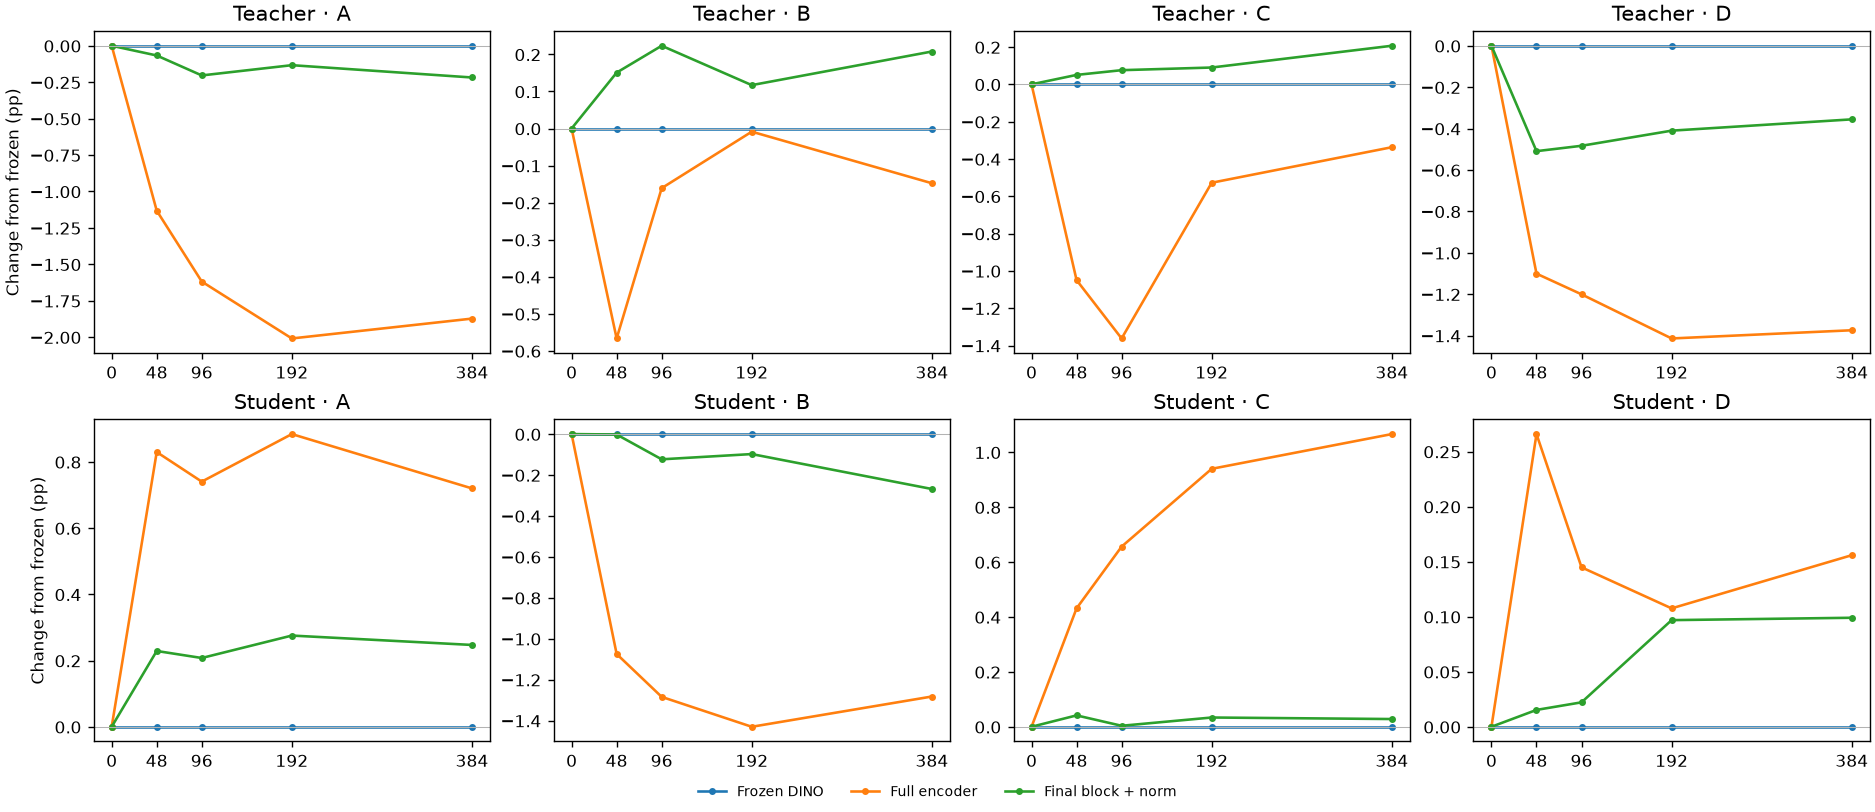